# Flickr8k training playground

Inspect actual images, caption tokens, augmentation, normalization, batches, masks,
and model shapes using the same functions as the training CLI. Run cells in order.
Change `CONFIG_PATH` below to inspect another configuration, then restart and run all.

Setup from the project root:
```bash
uv sync --extra eval --extra notebook
uv run --with kagglehub python scripts/setup_flickr8k.py
uv run jupyter lab notebooks/playground.ipynb
```

The first run may download the pinned Hugging Face tokenizer, processor, and ViT
weights. The forward preview uses a small CPU batch without optimizer updates;
its randomly initialized caption decoder does not produce meaningful captions.
SCST rollout inspection is optional because it retains a sampling gradient graph.


In [1]:
from pathlib import Path

CONFIG_PATH = "configs/default.toml"
IMAGE_INDEX = 0  # Index into the manifest's ordered training images.
AUGMENTATION_VARIANT = 0  # Change this for another reproducible random transform.
RUN_MODEL_FORWARD = True  # Loads real pinned ViT weights; no training updates.
MODEL_PREVIEW_BATCH = 1  # Full configured data batches are inspected separately.
RUN_SCST_ROLLOUT = False  # Optional, differentiable sampled rollout.
SCST_PREVIEW_ACTIONS = 8  # Explicit preview cap, not a change to training config.
TOKEN_LENGTH_SAMPLE_IMAGES = 256

# Support kernels launched from the project root or a nested directory.
ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src/scst_captioner").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Start Jupyter from inside the image-captioning-with-scst project.")

In [2]:
import dataclasses
import html
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, Markdown, display
from PIL import Image
from transformers import AutoConfig

from scst_captioner.cli import (
    _load_corpus,
    _load_hf_components,
    _loader,
    _make_reward,
    _train_augmentation,
)
from scst_captioner.config import load_config
from scst_captioner.data import (
    SCSTImageDataset,
    XECaptionDataset,
    collate_image_references,
    records_for_split,
)
from scst_captioner.generation import scst_rollouts
from scst_captioner.losses import reinforce_loss, token_cross_entropy_sum
from scst_captioner.model import CPTRCaptioner, build_model
from scst_captioner.reproducibility import seed_everything
from scst_captioner.tokenization import (
    decode_caption_batch,
    normalize_reward_text,
    resolve_special_token_ids,
)

os.chdir(ROOT)

config = load_config(CONFIG_PATH)
seed_everything(config.runtime.seed, deterministic=config.runtime.deterministic)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def table(headers, rows):
    def row(values, tag):
        return (
            "<tr>"
            + "".join(f"<{tag}>{html.escape(str(value))}</{tag}>" for value in values)
            + "</tr>"
        )

    display(
        HTML(
            "<table>"
            + row(headers, "th")
            + "".join(row(values, "td") for values in rows)
            + "</table>"
        )
    )


def tensor_rows(batch):
    return [
        (name, tuple(value.shape), str(value.dtype), str(value.device))
        for name, value in batch.items()
        if isinstance(value, torch.Tensor)
    ]


display(Markdown(f"**Loaded:** `{CONFIG_PATH}` · seed `{config.runtime.seed}`"))
print(json.dumps(config.to_dict(), indent=2))

**Loaded:** `configs/default.toml` · seed `42`

{
  "model": {
    "encoder_name": "google/vit-base-patch16-384",
    "encoder_revision": "2960116e809e2fca84146dbb240289aee7db4827",
    "tokenizer_name": "distilbert-base-uncased",
    "tokenizer_revision": "12040accade4e8a0f71eabdb258fecc2e7e948be",
    "max_seq_length": 80,
    "d_model": 768,
    "num_heads": 12,
    "feedforward_dim": 1536,
    "num_decoder_layers": 4,
    "dropout": 0.1,
    "activation": "relu",
    "freeze_encoder": true
  },
  "data": {
    "images_dir": "data/flickr8k/Images",
    "captions_file": "data/flickr8k/captions.txt",
    "split_manifest": "data/splits/flickr8k.json",
    "min_caption_words": 1,
    "expected_references_per_image": 5,
    "num_workers": 2,
    "horizontal_flip_probability": 0.4,
    "rotation_degrees": 10.0,
    "color_jitter_probability": 0.3,
    "brightness": 0.3,
    "hue": 0.1
  },
  "xe": {
    "epochs": 15,
    "batch_size": 40,
    "learning_rate": 0.0001,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "gradient_clip

## 1. Raw files and fixed image-level splits

The training loader parses the caption CSV, preserves punctuation and all five
annotations (including repeated text), and normalizes extra whitespace. The
manifest fixes image membership before caption rows are expanded. Validation
checks hashes, reference counts, full coverage, and disjoint splits.


Split,Images,Caption rows
train,6000,30000
validation / dev,1000,5000
test,1000,5000
excluded,91,outside the conventional split lists


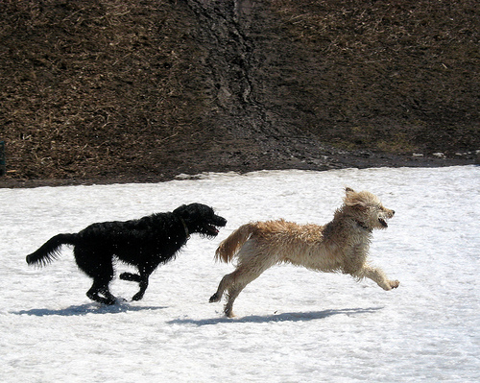

Field,Value
image_id,2513260012_03d33305cf.jpg
original mode,RGB
"RGB pixel array [H,W,C]","(399, 500, 3)"
pixel dtype / range,"uint8, 0-255"


Reference,Text
1,A black dog is running after a white dog in the snow .
2,Black dog chasing brown dog through snow
3,Two dogs chase each other across the snowy ground .
4,Two dogs play together in the snow .
5,Two dogs running through a low lying body of water .


In [3]:
records, manifest = _load_corpus(config)
train_records = records_for_split(records, manifest, "train", validate=False)
validation_records = records_for_split(records, manifest, "validation", validate=False)
test_records = records_for_split(records, manifest, "test", validate=False)
table(
    ["Split", "Images", "Caption rows"],
    [
        ("train", len(train_records), sum(len(r.captions) for r in train_records)),
        (
            "validation / dev",
            len(validation_records),
            sum(len(r.captions) for r in validation_records),
        ),
        ("test", len(test_records), sum(len(r.captions) for r in test_records)),
        ("excluded", len(manifest.excluded), "outside the conventional split lists"),
    ],
)
assert set(manifest.train).isdisjoint(manifest.validation)
assert set(manifest.train).isdisjoint(manifest.test)
assert set(manifest.validation).isdisjoint(manifest.test)
if not 0 <= IMAGE_INDEX < len(train_records):
    raise ValueError("IMAGE_INDEX is outside the training split.")
record = train_records[IMAGE_INDEX]
with Image.open(record.image_path) as source:
    original_mode = source.mode
    original = source.convert("RGB")
display(original.resize((480, round(480 * original.height / original.width))))
table(
    ["Field", "Value"],
    [
        ("image_id", record.image_id),
        ("original mode", original_mode),
        ("RGB pixel array [H,W,C]", np.asarray(original).shape),
        ("pixel dtype / range", f"{np.asarray(original).dtype}, 0-255"),
    ],
)
table(["Reference", "Text"], enumerate(record.captions, start=1))

## 2. The pinned tokenizer and ViT processor

These are loaded by the same helper used for training. The tokenizer has an
existing vocabulary; no vocabulary is fitted on validation or test captions.
The processor owns resizing, rescaling, and normalization.


In [4]:
tokenizer, processor = _load_hf_components(config)
special = resolve_special_token_ids(tokenizer)
vision_config = AutoConfig.from_pretrained(
    config.model.encoder_name, revision=config.model.encoder_revision
)
table(
    ["Setting", "Resolved value"],
    [
        (
            "tokenizer / revision",
            f"{config.model.tokenizer_name} / {config.model.tokenizer_revision}",
        ),
        ("vocabulary size", len(tokenizer)),
        ("start / end / padding IDs", (special.bos, special.eos, special.pad)),
        (
            "start / end / padding tokens",
            tokenizer.convert_ids_to_tokens([special.bos, special.eos, special.pad]),
        ),
        ("processor resize", processor.size),
        ("rescale enabled / factor", (processor.do_rescale, processor.rescale_factor)),
        ("normalization enabled", processor.do_normalize),
        ("channel means", processor.image_mean),
        ("channel standard deviations", processor.image_std),
        ("maximum decoder length", config.model.max_seq_length),
    ],
)

Setting,Resolved value
tokenizer / revision,distilbert-base-uncased / 12040accade4e8a0f71eabdb258fecc2e7e948be
vocabulary size,30522
start / end / padding IDs,"(101, 102, 0)"
start / end / padding tokens,"['[CLS]', '[SEP]', '[PAD]']"
processor resize,"{'height': 384, 'width': 384}"
rescale enabled / factor,"(True, 0.00392156862745098)"
normalization enabled,True
channel means,"[0.5, 0.5, 0.5]"
channel standard deviations,"[0.5, 0.5, 0.5]"
maximum decoder length,80


## 3. Augmentation in pixel space

Training applies the configured transforms in order to the RGB PIL image. The
strip below traces one actual composition, followed by several independent
views. Random transforms can choose an identity operation on a particular draw.
Validation and test skip this augmentation composition.


Compose(
    RandomHorizontalFlip(p=0.4)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    RandomApply(
    p=0.3
    ColorJitter(brightness=(0.7, 1.3), contrast=None, saturation=None, hue=(-0.1, 0.1))
)
)


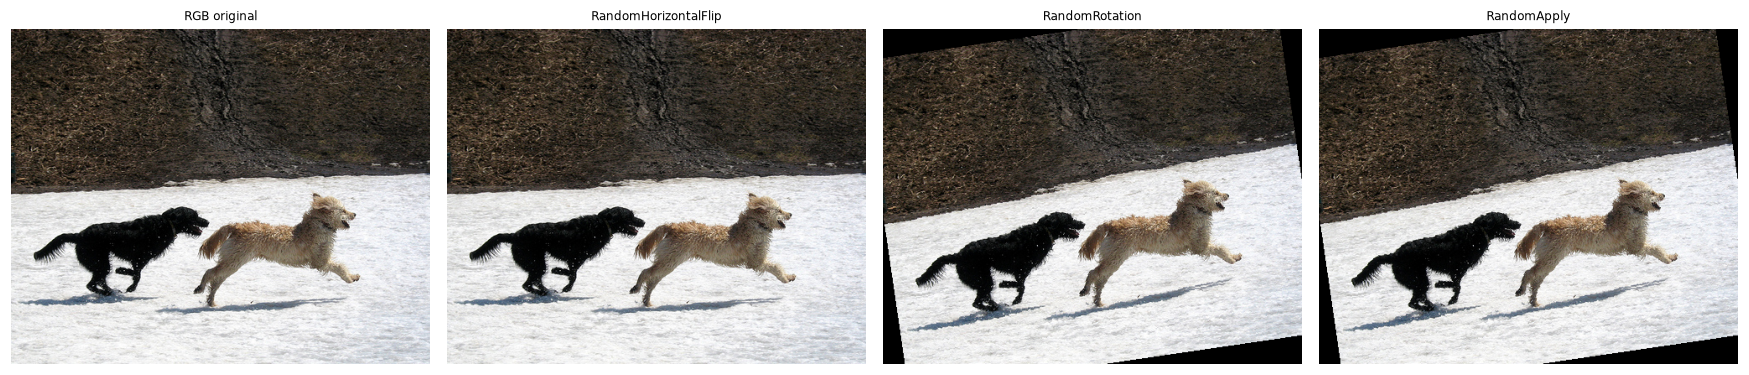

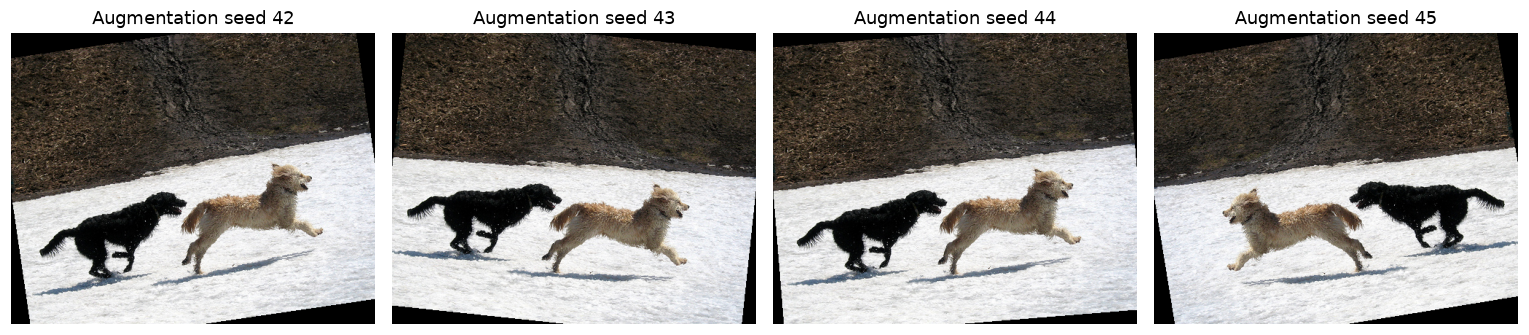

In [5]:
augmentation = _train_augmentation(config)
print(augmentation)
preview_seed = config.runtime.seed + AUGMENTATION_VARIANT
seed_everything(preview_seed)
stage_images = [original.copy()]
stage_names = ["RGB original"]
current = original.copy()
for transform in augmentation.transforms:
    current = transform(current)
    stage_images.append(current.copy())
    stage_names.append(type(transform).__name__)
augmented = current
fig, axes = plt.subplots(1, len(stage_images), figsize=(16, 4))
for ax, image, name in zip(axes, stage_images, stage_names, strict=True):
    ax.imshow(image)
    ax.set_title(name, fontsize=8, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for index, ax in enumerate(axes):
    seed_everything(preview_seed + index)
    ax.imshow(augmentation(original.copy()))
    ax.set_title(f"Augmentation seed {preview_seed + index}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Apply the model-provided ViT image processor

`processor` is the actual Hugging Face `ViTImageProcessor` loaded in section 2
by the training helper, using the encoder name and pinned revision from the
selected config. Its published settings control resizing, rescaling, and
normalization. The table below shows the live processor and its settings.

The preprocessing happens in this call:
```python
processed = processor(images=augmented, return_tensors="pt")["pixel_values"]
```

It returns `[1,C,H,W]`; a dataset item removes only the leading singleton
batch dimension. These normalized values go to the ViT.

**Display only:** the later `restored` calculation reverses normalization to
show the resized image as ordinary RGB. It does not implement preprocessing
or change the tensor sent to the model. The channel heatmaps show the actual
normalized model inputs. The patch grid is also a visualization; the ViT
creates patch embeddings internally.

**Loaded from the model checkpoint in section 2:**

```python
processor = ViTImageProcessor.from_pretrained(
    config.model.encoder_name,
    revision=config.model.encoder_revision,
)
```

Model-provided processor setting,Actual value
processor class,transformers.models.vit.image_processing_vit.ViTImageProcessor
encoder checkpoint,google/vit-base-patch16-384
pinned revision,2960116e809e2fca84146dbb240289aee7db4827
resize enabled / size,"(True, {'height': 384, 'width': 384})"
resize interpolation,2
rescale enabled / factor,"(True, 0.00392156862745098)"
normalize enabled,True
channel means,"[0.5, 0.5, 0.5]"
channel standard deviations,"[0.5, 0.5, 0.5]"


Stage,Shape,dtype,Range
RGB PIL array,"(399, 500, 3)",uint8,0-255
processor output,"(1, 3, 384, 384)",torch.float32,-1.000 to 1.000
dataset pixel_values,"(3, 384, 384)",torch.float32,-1.000 to 1.000


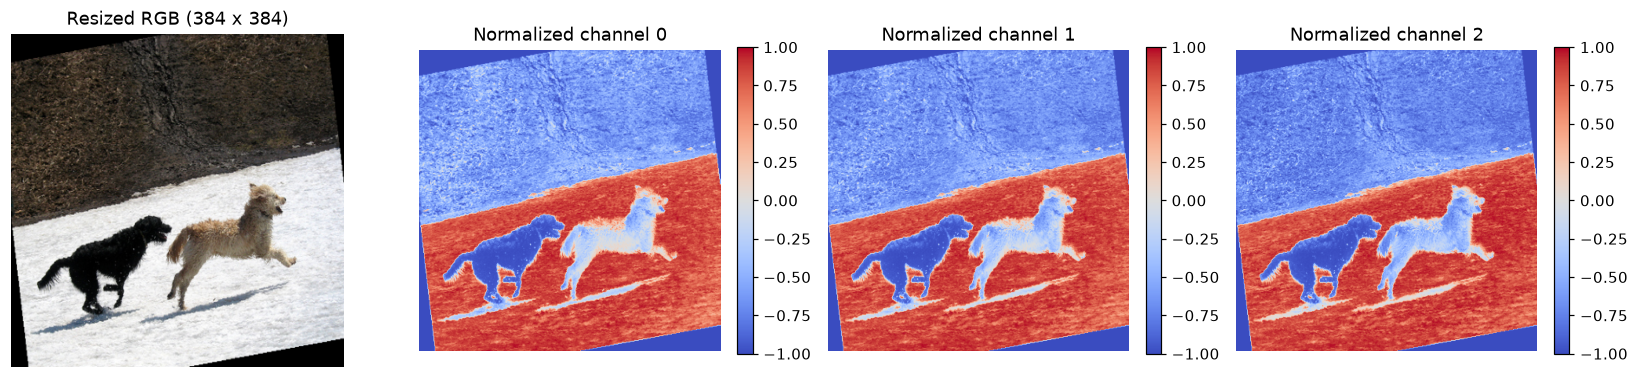

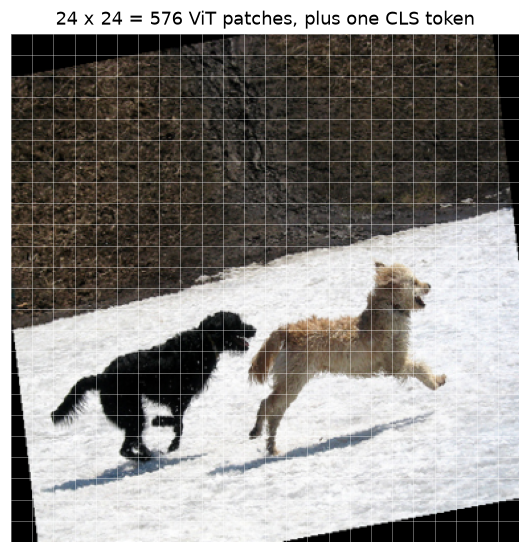

In [6]:
display(Markdown("**Loaded from the model checkpoint in section 2:**"))
display(
    Markdown(
        "```python\nprocessor = ViTImageProcessor.from_pretrained(\n    config.model.encoder_name,\n    revision=config.model.encoder_revision,\n)\n```"
    )
)
table(
    ["Model-provided processor setting", "Actual value"],
    [
        ("processor class", f"{type(processor).__module__}.{type(processor).__name__}"),
        ("encoder checkpoint", config.model.encoder_name),
        ("pinned revision", config.model.encoder_revision),
        ("resize enabled / size", (processor.do_resize, processor.size)),
        ("resize interpolation", str(processor.resample)),
        ("rescale enabled / factor", (processor.do_rescale, processor.rescale_factor)),
        ("normalize enabled", processor.do_normalize),
        ("channel means", processor.image_mean),
        ("channel standard deviations", processor.image_std),
    ],
)

# Actual preprocessing: the model-provided processor performs these operations.
processed = processor(images=augmented, return_tensors="pt")["pixel_values"]
pixels = processed[0]
height, width = pixels.shape[-2:]
# Visualization only: reverse normalization without changing model inputs.
restored = pixels.clone()
if processor.do_normalize:
    restored = restored * torch.tensor(processor.image_std)[:, None, None]
    restored = restored + torch.tensor(processor.image_mean)[:, None, None]
display_rgb = restored.permute(1, 2, 0).numpy()
if not processor.do_rescale:
    display_rgb = display_rgb / 255.0
table(
    ["Stage", "Shape", "dtype", "Range"],
    [
        ("RGB PIL array", np.asarray(augmented).shape, "uint8", "0-255"),
        (
            "processor output",
            tuple(processed.shape),
            processed.dtype,
            f"{processed.min():.3f} to {processed.max():.3f}",
        ),
        (
            "dataset pixel_values",
            tuple(pixels.shape),
            pixels.dtype,
            f"{pixels.min():.3f} to {pixels.max():.3f}",
        ),
    ],
)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(display_rgb.clip(0, 1))
axes[0].set_title(f"Resized RGB ({width} x {height})")
for channel, ax in enumerate(axes[1:]):
    heat = ax.imshow(
        pixels[channel], cmap="coolwarm", vmin=float(pixels.min()), vmax=float(pixels.max())
    )
    ax.set_title(f"Normalized channel {channel}")
    fig.colorbar(heat, ax=ax, fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

patch_size = vision_config.patch_size
patch_h, patch_w = (patch_size, patch_size) if isinstance(patch_size, int) else patch_size
patch_count = (height // patch_h) * (width // patch_w)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(display_rgb.clip(0, 1))
for x in range(0, width + 1, patch_w):
    ax.axvline(x - 0.5, color="white", linewidth=0.35, alpha=0.65)
for y in range(0, height + 1, patch_h):
    ax.axhline(y - 0.5, color="white", linewidth=0.35, alpha=0.65)
ax.set_title(
    f"{height // patch_h} x {width // patch_w} = {patch_count} ViT patches, plus one CLS token"
)
ax.axis("off")
plt.show()

## 5. WordPiece IDs, teacher-forcing shift, and padding

XE builds one row per human caption. The tokenizer adds start/end tokens and
limits the encoded sequence to `max_seq_length + 1`; slicing then creates
input and target sequences of at most `max_seq_length`, padded to that length.
Input position `t` predicts target position `t`. The decoder's causal mask
prevents access to future input tokens. Target PAD positions do not contribute
to XE loss; this is distinct from masking PAD keys inside attention.


In [7]:
xe_train = XECaptionDataset(
    train_records,
    tokenizer=tokenizer,
    image_processor=processor,
    max_seq_length=config.model.max_seq_length,
    pil_transform=augmentation,
)
xe_validation = XECaptionDataset(
    validation_records,
    tokenizer=tokenizer,
    image_processor=processor,
    max_seq_length=config.model.max_seq_length,
)
sample_row = sum(len(r.captions) for r in train_records[:IMAGE_INDEX])
seed_everything(preview_seed)
item = xe_train[sample_row]
assert torch.equal(item["pixel_values"], pixels), (
    "Visual trace must match the actual dataset transform."
)
caption = item["caption"]
full_ids = tokenizer(caption, add_special_tokens=True)["input_ids"]
limited_ids = tokenizer(
    caption, add_special_tokens=True, truncation=True, max_length=config.model.max_seq_length + 1
)["input_ids"]
display(Markdown(f"**Caption:** {caption}"))
table(
    ["Measure", "Value"],
    [
        ("word count (not WordPiece count)", len(caption.split())),
        ("IDs including start/end before truncation", len(full_ids)),
        ("IDs after truncation", len(limited_ids)),
        ("input / target shape", (tuple(item["input_ids"].shape), tuple(item["labels"].shape))),
        ("active loss targets", int(item["labels"].ne(special.pad).sum())),
    ],
)
input_tokens = tokenizer.convert_ids_to_tokens(item["input_ids"].tolist())
target_tokens = tokenizer.convert_ids_to_tokens(item["labels"].tolist())
table(
    ["Position", "Input ID", "Input token", "Target ID", "Target token", "Included in loss?"],
    [
        (
            index,
            int(input_id),
            input_token,
            int(target_id),
            target_token,
            int(target_id) != special.pad,
        )
        for index, (input_id, input_token, target_id, target_token) in enumerate(
            zip(item["input_ids"], input_tokens, item["labels"], target_tokens, strict=True)
        )
    ],
)
assert torch.equal(
    item["input_ids"][1 : len(limited_ids) - 1], item["labels"][: len(limited_ids) - 2]
)

**Caption:** A black dog is running after a white dog in the snow .

Measure,Value
word count (not WordPiece count),13
IDs including start/end before truncation,15
IDs after truncation,15
input / target shape,"((80,), (80,))"
active loss targets,14


Position,Input ID,Input token,Target ID,Target token,Included in loss?
0,101,[CLS],1037,a,True
1,1037,a,2304,black,True
2,2304,black,3899,dog,True
3,3899,dog,2003,is,True
4,2003,is,2770,running,True
5,2770,running,2044,after,True
6,2044,after,1037,a,True
7,1037,a,2317,white,True
8,2317,white,3899,dog,True
9,3899,dog,1999,in,True


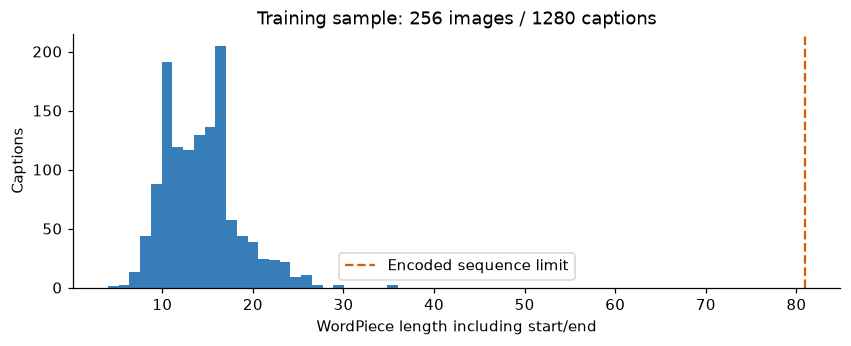

Captions requiring truncation in this sample: 0


In [8]:
# Inspect lengths on a declared TRAINING-only sample, not on the test split.
length_records = train_records[: min(TOKEN_LENGTH_SAMPLE_IMAGES, len(train_records))]
length_captions = [caption for r in length_records for caption in r.captions]
lengths = np.array(
    [
        len(ids)
        for ids in tokenizer(length_captions, add_special_tokens=True, truncation=False)[
            "input_ids"
        ]
    ]
)
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(lengths, bins=min(40, max(1, len(set(lengths.tolist())))), color="#377eb8")
ax.axvline(
    config.model.max_seq_length + 1, color="#d95f02", linestyle="--", label="Encoded sequence limit"
)
ax.set(
    xlabel="WordPiece length including start/end",
    ylabel="Captions",
    title=f"Training sample: {len(length_records)} images / {len(lengths)} captions",
)
ax.legend()
plt.show()
print(
    f"Captions requiring truncation in this sample: {(lengths > config.model.max_seq_length + 1).sum()}"
)

## 6. Real configured XE and SCST batches

Batch sizes come directly from the selected TOML. Only this notebook's worker
count is set to zero for portable interactive execution; training retains the
configured worker count. Both use the training loader helper and its shuffle
generator. XE repeats an image across its caption rows; SCST batches unique
images and keeps references image-major (`references[image][caption]`).


Configured workers: 2; notebook preview workers: 0


XE tensor,Shape,dtype,Device
caption_index,"(40,)",torch.int64,cpu
input_ids,"(40, 80)",torch.int64,cpu
labels,"(40, 80)",torch.int64,cpu
pixel_values,"(40, 3, 384, 384)",torch.float32,cpu


SCST tensor,Shape,dtype,Device
pixel_values,"(12, 3, 384, 384)",torch.float32,cpu


Stage,Dataset entries,Configured batch,Batches / epoch
XE train,30000,40,750
XE validation,5000,40,125
SCST train,6000,12,500


SCST field,Structure
image_ids,list of 12 IDs
references,12 images x 5 captions


First SCST image,Reference
2836703077_fa9c736203.jpg,Two children are in a blue amusement park ride .
2836703077_fa9c736203.jpg,"Two children on a carnival ride , tree in background ."
2836703077_fa9c736203.jpg,two children on a ride
2836703077_fa9c736203.jpg,Two children riding a blue rollercoaster smile .
2836703077_fa9c736203.jpg,Two kids ride an amusement park ride .


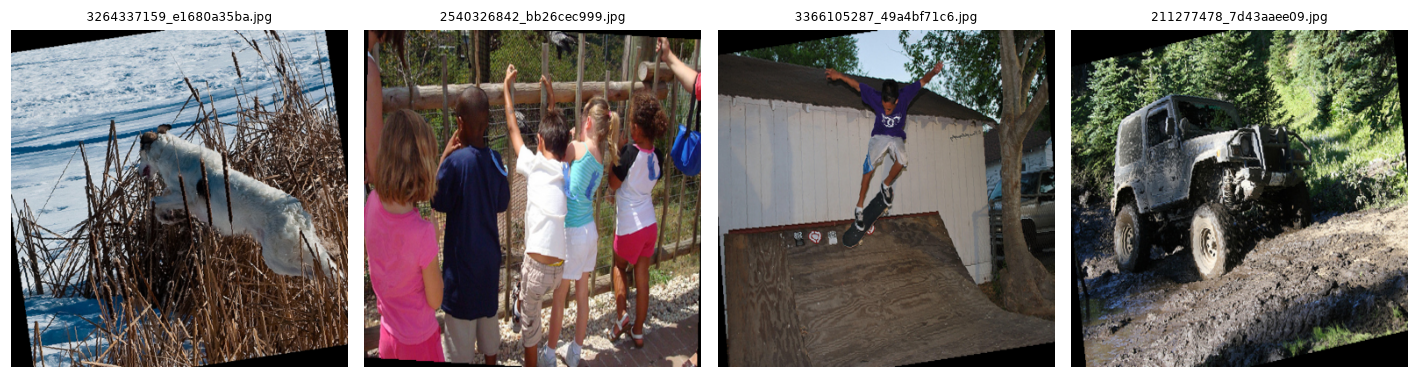

In [9]:
preview_config = dataclasses.replace(config, data=dataclasses.replace(config.data, num_workers=0))
print(f"Configured workers: {config.data.num_workers}; notebook preview workers: 0")
seed_everything(config.runtime.seed)
xe_loader = _loader(xe_train, batch_size=config.xe.batch_size, shuffle=True, config=preview_config)
xe_batch = next(iter(xe_loader))
scst_train = SCSTImageDataset(
    train_records,
    image_processor=processor,
    pil_transform=augmentation,
    expected_references_per_image=config.data.expected_references_per_image,
)
scst_loader = _loader(
    scst_train,
    batch_size=config.scst.batch_size,
    shuffle=True,
    config=preview_config,
    collate_fn=collate_image_references,
)
scst_batch = next(iter(scst_loader))
table(["XE tensor", "Shape", "dtype", "Device"], tensor_rows(xe_batch))
table(["SCST tensor", "Shape", "dtype", "Device"], tensor_rows(scst_batch))
table(
    ["Stage", "Dataset entries", "Configured batch", "Batches / epoch"],
    [
        ("XE train", len(xe_train), config.xe.batch_size, len(xe_loader)),
        (
            "XE validation",
            len(xe_validation),
            config.xe.batch_size,
            (len(xe_validation) + config.xe.batch_size - 1) // config.xe.batch_size,
        ),
        ("SCST train", len(scst_train), config.scst.batch_size, len(scst_loader)),
    ],
)
table(
    ["SCST field", "Structure"],
    [
        ("image_ids", f"list of {len(scst_batch['image_ids'])} IDs"),
        (
            "references",
            f"{len(scst_batch['references'])} images x {len(scst_batch['references'][0])} captions",
        ),
    ],
)
assert len(set(scst_batch["image_ids"])) == len(scst_batch["image_ids"])
table(
    ["First SCST image", "Reference"],
    [(scst_batch["image_ids"][0], ref) for ref in scst_batch["references"][0]],
)
fig, axes = plt.subplots(1, min(4, len(xe_batch["pixel_values"])), figsize=(13, 4), squeeze=False)
for index, ax in enumerate(axes[0]):
    image = xe_batch["pixel_values"][index].clone()
    if processor.do_normalize:
        image = (
            image * torch.tensor(processor.image_std)[:, None, None]
            + torch.tensor(processor.image_mean)[:, None, None]
        )
    if not processor.do_rescale:
        image = image / 255.0
    ax.imshow(image.permute(1, 2, 0).numpy().clip(0, 1))
    ax.set_title(xe_batch["image_id"][index], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Attention masks and loss masks

In the decoder's boolean attention masks, **True means blocked**. The upper
triangle blocks future positions. The key-padding mask blocks PAD keys. In the
separate loss mask, **True means included**, so its meaning is reversed.


Mask,Shape,True means
causal attention,"(80, 80)",future key blocked
key padding,"(40, 80)",PAD key blocked
XE loss,"(40, 80)",target included


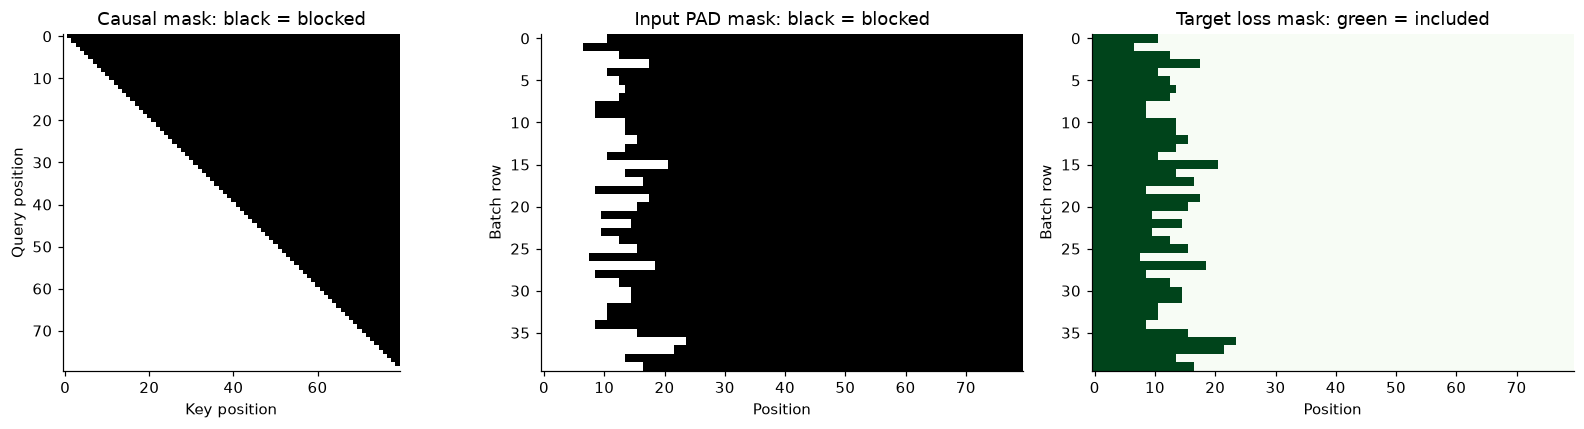

In [10]:
causal_mask = CPTRCaptioner.compute_causal_mask(xe_batch["input_ids"])
padding_mask = xe_batch["input_ids"].eq(special.pad)
loss_mask = xe_batch["labels"].ne(special.pad)
table(
    ["Mask", "Shape", "True means"],
    [
        ("causal attention", tuple(causal_mask.shape), "future key blocked"),
        ("key padding", tuple(padding_mask.shape), "PAD key blocked"),
        ("XE loss", tuple(loss_mask.shape), "target included"),
    ],
)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(causal_mask.numpy(), cmap="Greys", vmin=0, vmax=1)
axes[0].set(title="Causal mask: black = blocked", xlabel="Key position", ylabel="Query position")
axes[1].imshow(padding_mask.numpy(), cmap="Greys", vmin=0, vmax=1, aspect="auto")
axes[1].set(title="Input PAD mask: black = blocked", xlabel="Position", ylabel="Batch row")
axes[2].imshow(loss_mask.numpy(), cmap="Greens", vmin=0, vmax=1, aspect="auto")
axes[2].set(title="Target loss mask: green = included", xlabel="Position", ylabel="Batch row")
plt.tight_layout()
plt.show()

## 8. ViT → decoder → vocabulary logits

This cell loads the actual pinned encoder and constructs the production decoder.
The decoder is newly initialized. It runs one small **CPU, float32, evaluation-mode**
forward pass with the configured sequence length; actual XE training enables
decoder dropout and optionally CUDA AMP. No optimizer or checkpoint is modified.
The captured internal shapes come from production module hooks.


Module,Training mode during XE,Trainable parameters
ViT backbone,False,0
caption decoder,True,28363776


Production module output,Observed shape,dtype
ViT hidden states,"(1, 577, 768)",torch.float32
projected visual memory,"(1, 577, 768)",torch.float32
scaled token embeddings,"(1, 80, 768)",torch.float32
embeddings + sinusoidal positions,"(1, 80, 768)",torch.float32
decoder hidden states,"(1, 80, 768)",torch.float32
vocabulary logits,"(1, 80, 30522)",torch.float32


XE loss quantity,Observed value
flattened logits,"(80, 30522)"
flattened targets,"(80,)"
active target count,11
summed cross entropy,117.68563842773438
mean non-PAD cross entropy,10.698694229125977


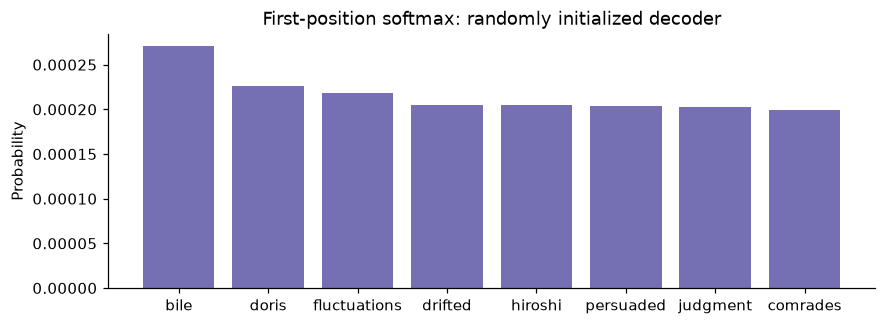

In [11]:
model = None
if RUN_MODEL_FORWARD:
    if MODEL_PREVIEW_BATCH < 1:
        raise ValueError("MODEL_PREVIEW_BATCH must be positive.")
    seed_everything(config.runtime.seed)
    model = build_model(config.model, tokenizer).cpu()
    model.train()
    table(
        ["Module", "Training mode during XE", "Trainable parameters"],
        [
            (
                "ViT backbone",
                model.backbone.backbone.training,
                sum(p.numel() for p in model.backbone.parameters() if p.requires_grad),
            ),
            (
                "caption decoder",
                model.decoder.training,
                sum(p.numel() for p in model.decoder.parameters() if p.requires_grad),
            ),
        ],
    )
    model.eval()
    preview_size = min(MODEL_PREVIEW_BATCH, len(xe_batch["input_ids"]))
    forward_pixels = xe_batch["pixel_values"][:preview_size]
    forward_ids = xe_batch["input_ids"][:preview_size]
    forward_labels = xe_batch["labels"][:preview_size]
    captured = []

    def capture(name):
        def hook(module, inputs, output):
            captured.append((name, tuple(output.shape), str(output.dtype)))

        return hook

    hooks = [
        module.register_forward_hook(capture(name))
        for name, module in [
            ("ViT hidden states", model.backbone),
            ("projected visual memory", model.memory_projection),
            ("scaled token embeddings", model.positional_embedding.embedding),
            ("embeddings + sinusoidal positions", model.positional_embedding),
            ("decoder hidden states", model.decoder),
            ("vocabulary logits", model.fc),
        ]
    ]
    try:
        with torch.no_grad():
            logits = model(forward_pixels, forward_ids)
            loss_sum, correct, active_targets = token_cross_entropy_sum(
                logits, forward_labels, special.pad
            )
    finally:
        for hook in hooks:
            hook.remove()
    table(["Production module output", "Observed shape", "dtype"], captured)
    assert logits.shape == (preview_size, config.model.max_seq_length, len(tokenizer))
    assert torch.isfinite(logits).all()
    table(
        ["XE loss quantity", "Observed value"],
        [
            ("flattened logits", (preview_size * config.model.max_seq_length, len(tokenizer))),
            ("flattened targets", (preview_size * config.model.max_seq_length,)),
            ("active target count", active_targets),
            ("summed cross entropy", float(loss_sum)),
            ("mean non-PAD cross entropy", float(loss_sum / active_targets)),
        ],
    )
    probabilities = logits[0, 0].softmax(dim=-1)
    values, indices = probabilities.topk(8)
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.bar(tokenizer.convert_ids_to_tokens(indices.tolist()), values.numpy(), color="#7570b3")
    ax.set(title="First-position softmax: randomly initialized decoder", ylabel="Probability")
    plt.show()
else:
    print("Model forward skipped; enable RUN_MODEL_FORWARD in the controls cell.")

### Token embeddings, positions, and dropout

These heatmaps show the actual embedding transform for the preview caption:
scaled learned embeddings, fixed sinusoidal positions, their sum, and the
training-mode dropout result. Displayed positions and feature dimensions are
cropped only for readability; tensors retain the configured length and width.
PAD token embeddings start at zero, but positional encoding still adds values
there; the attention and target-loss masks handle padding separately.

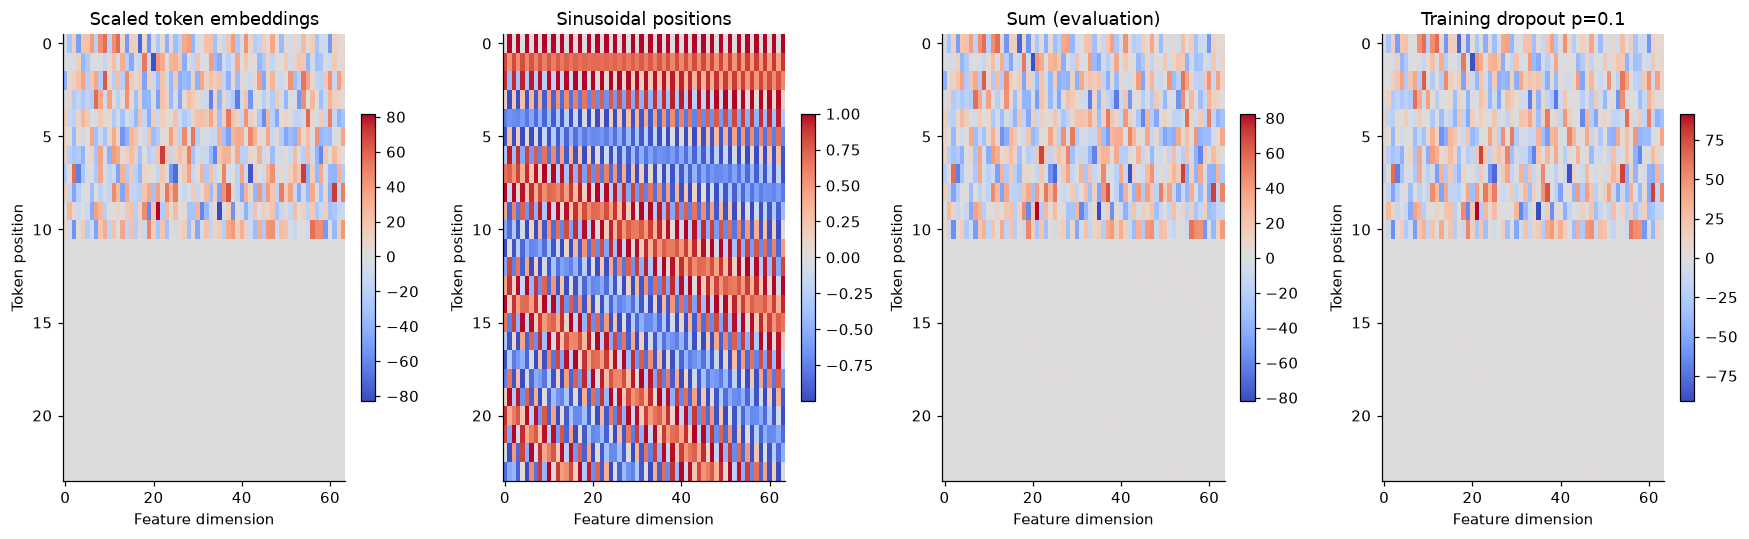

In [12]:
if model is not None:
    embedding = model.positional_embedding
    with torch.no_grad():
        scaled = embedding.embedding(forward_ids)
        positional = embedding.positional_encoding.pe[:, : forward_ids.size(1)]
        embedding.eval()
        eval_embeddings = embedding(forward_ids)
        embedding.train()
        seed_everything(config.runtime.seed)
        train_embeddings = embedding(forward_ids)
        embedding.eval()
    positions_shown = min(config.model.max_seq_length, 24)
    features_shown = min(config.model.d_model, 64)
    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    panels = [
        ("Scaled token embeddings", scaled),
        ("Sinusoidal positions", positional),
        ("Sum (evaluation)", eval_embeddings),
        (f"Training dropout p={config.model.dropout}", train_embeddings),
    ]
    for ax, (title, values) in zip(axes, panels, strict=True):
        image = ax.imshow(
            values[0, :positions_shown, :features_shown].numpy(), aspect="auto", cmap="coolwarm"
        )
        ax.set(title=title, xlabel="Feature dimension", ylabel="Token position")
        fig.colorbar(image, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()
    assert torch.allclose(eval_embeddings, scaled + positional)
else:
    print("Embedding visualization requires RUN_MODEL_FORWARD.")

In [13]:
# Derived full-training dimensions; attention score matrices are conceptual,
# because PyTorch may use fused attention without materializing these arrays.
B, L, D, H, V = (
    config.xe.batch_size,
    config.model.max_seq_length,
    config.model.d_model,
    config.model.num_heads,
    len(tokenizer),
)
M = patch_count + 1
table(
    ["Full XE batch stage", "Shape", "Meaning"],
    [
        ("pixels", (B, 3, height, width), "batch, channels, height, width"),
        ("visual memory", (B, M, D), "patches + CLS, projected to decoder width"),
        ("caption embeddings", (B, L, D), "input tokens x decoder width"),
        ("per-head queries", (B, H, L, D // H), "decoder multi-head attention"),
        ("self-attention scores (conceptual)", (B, H, L, L), "caption queries x caption keys"),
        ("cross-attention scores (conceptual)", (B, H, L, M), "caption queries x visual keys"),
        (
            "feed-forward intermediate",
            (B, L, config.model.feedforward_dim),
            "inside each decoder layer",
        ),
        ("vocabulary logits", (B, L, V), "one vocabulary distribution per input position"),
    ],
)
print(f"Decoder layers: {config.model.num_decoder_layers}; heads: {H}; head width: {D // H}")
print(f"A full float32 XE logits tensor alone is {B * L * V * 4 / 1024**2:.1f} MiB.")

Full XE batch stage,Shape,Meaning
pixels,"(40, 3, 384, 384)","batch, channels, height, width"
visual memory,"(40, 577, 768)","patches + CLS, projected to decoder width"
caption embeddings,"(40, 80, 768)",input tokens x decoder width
per-head queries,"(40, 12, 80, 64)",decoder multi-head attention
self-attention scores (conceptual),"(40, 12, 80, 80)",caption queries x caption keys
cross-attention scores (conceptual),"(40, 12, 80, 577)",caption queries x visual keys
feed-forward intermediate,"(40, 80, 1536)",inside each decoder layer
vocabulary logits,"(40, 80, 30522)",one vocabulary distribution per input position


Decoder layers: 4; heads: 12; head width: 64
A full float32 XE logits tensor alone is 372.6 MiB.


## 9. SCST text preparation and training-only reward corpus

The configured reward is constructed using **training references only**. CIDEr-D
uses fixed training-corpus document frequencies. The current CIDEr-D protocol
appends a completion marker to references and captions that generated EOS.
Reward text normalization handles WordPiece punctuation boundaries symmetrically.
This reward convention is separate from the PTB tokenization used for reported
COCO evaluation metrics.


In [14]:
reward, include_eos = _make_reward(config, train_records)
reference = record.captions[0]
reference_ids = tokenizer(reference, add_special_tokens=True)["input_ids"]
roundtrip = decode_caption_batch(tokenizer, [reference_ids])[0]
prepared_reference = f"{reference} <eos>" if include_eos else reference
prepared_roundtrip = f"{roundtrip} <eos>" if include_eos else roundtrip
table(
    ["Text stage", "Value"],
    [
        ("original reference (whitespace normalized)", reference),
        ("decoded WordPiece caption", roundtrip),
        ("reward reference normalization", normalize_reward_text(prepared_reference).casefold()),
        ("reward prediction normalization", normalize_reward_text(prepared_roundtrip).casefold()),
        ("configured reward", config.scst.reward),
        ("completion marker included", include_eos),
    ],
)
reward_references = [[f"{ref} <eos>" if include_eos else ref for ref in record.captions]]
reference_score = reward([prepared_roundtrip], reward_references)
print("Reward for the tokenized-and-decoded human reference:", reference_score)

Text stage,Value
original reference (whitespace normalized),A black dog is running after a white dog in the snow .
decoded WordPiece caption,a black dog is running after a white dog in the snow.
reward reference normalization,a black dog is running after a white dog in the snow . <eos>
reward prediction normalization,a black dog is running after a white dog in the snow . <eos>
configured reward,cider_d
completion marker included,True


Reward for the tokenized-and-decoded human reference: (2.423884628546884,)


## 10. SCST action shapes and first-EOS masking

SCST generates one stochastic caption and one greedy baseline per image. The
sampled action log probabilities retain gradients; the baseline reward does not.
For `S` generated actions (at most the configured decoder length), token IDs
include the initial BOS and have length `S+1`. The first EOS contributes to loss;
later actions for that image do not. The following small **illustration** forces
different EOS positions so the rule is visible; its rewards are not model results.


SCST quantity,Training shape
pixels,"(12, 3, 384, 384)"
references,12 images x 5 strings
sampled / greedy token IDs,"[B, 1+S], B=12, S≤80"
sampled action log probabilities,"[B,S]"
first-EOS action mask,"[B,S]"
sample reward / baseline reward / advantage,[B]
REINFORCE loss,scalar


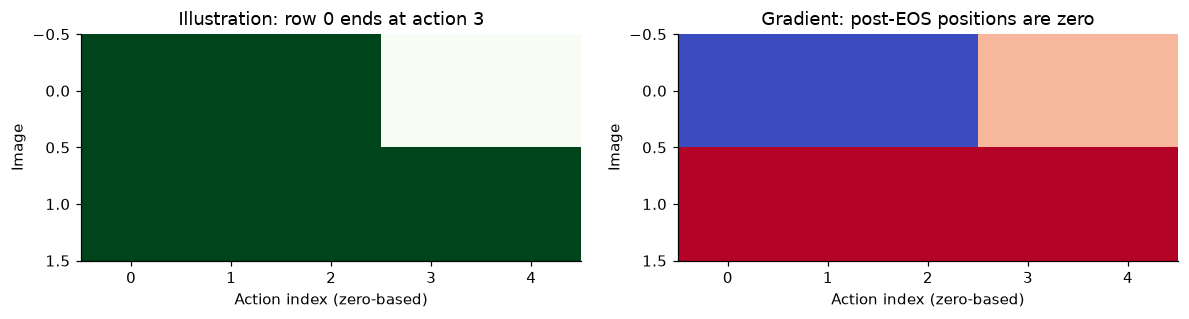

In [15]:
table(
    ["SCST quantity", "Training shape"],
    [
        ("pixels", (config.scst.batch_size, 3, height, width)),
        (
            "references",
            f"{config.scst.batch_size} images x {config.data.expected_references_per_image} strings",
        ),
        (
            "sampled / greedy token IDs",
            f"[B, 1+S], B={config.scst.batch_size}, S≤{config.model.max_seq_length}",
        ),
        ("sampled action log probabilities", "[B,S]"),
        ("first-EOS action mask", "[B,S]"),
        ("sample reward / baseline reward / advantage", "[B]"),
        ("REINFORCE loss", "scalar"),
    ],
)
illustration_mask = torch.tensor([[True, True, True, False, False], [True, True, True, True, True]])
illustration_log_probs = torch.full((2, 5), -1.0, requires_grad=True)
illustration_advantage = torch.tensor([0.5, -0.25])
illustration_loss = reinforce_loss(
    illustration_advantage, illustration_log_probs, illustration_mask
)
illustration_loss.backward()
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].imshow(illustration_mask, cmap="Greens", vmin=0, vmax=1, aspect="auto")
axes[0].set(
    title="Illustration: row 0 ends at action 3", xlabel="Action index (zero-based)", ylabel="Image"
)
axes[1].imshow(illustration_log_probs.grad, cmap="coolwarm", aspect="auto")
axes[1].set(
    title="Gradient: post-EOS positions are zero",
    xlabel="Action index (zero-based)",
    ylabel="Image",
)
plt.tight_layout()
plt.show()
assert torch.equal(illustration_log_probs.grad[0, 3:], torch.zeros(2))

## 11. Optional real greedy/sample rollout

Enable `RUN_SCST_ROLLOUT` in the controls cell and rerun from the beginning.
This uses the production rollout function, retains sampled gradients, and shows
the actual first-EOS mask. To keep the preview small it uses one image and the
explicit `SCST_PREVIEW_ACTIONS` cap. Training uses the full configured batch and
`max_seq_length` action budget. Captions here come from an untrained decoder.


In [16]:
if RUN_SCST_ROLLOUT:
    if model is None:
        raise RuntimeError("Enable RUN_MODEL_FORWARD before inspecting actual rollouts.")
    if SCST_PREVIEW_ACTIONS < 1:
        raise ValueError("SCST_PREVIEW_ACTIONS must be positive.")
    action_budget = min(SCST_PREVIEW_ACTIONS, config.model.max_seq_length)
    model.train()
    seed_everything(config.runtime.seed)
    rollouts = scst_rollouts(
        model,
        scst_batch["pixel_values"][:1],
        bos_token_id=special.bos,
        eos_token_id=special.eos,
        max_new_tokens=action_budget,
        forbidden_token_ids=special.forbidden,
        sample_model_mode=config.scst.sample_model_mode,
    )
    rollout_rows = []
    for name, output in [
        ("greedy baseline", rollouts.baseline),
        ("stochastic sample", rollouts.sampled),
    ]:
        text = decode_caption_batch(tokenizer, output.token_ids)[0]
        completed = bool((output.action_token_ids.eq(special.eos) & output.action_mask).any())
        if include_eos and completed:
            text = f"{text} <eos>".strip()
        rollout_rows.append(
            (name, tuple(output.token_ids.shape), tuple(output.action_mask.shape), text)
        )
    table(["Rollout", "Token IDs", "Action mask", "Decoded reward text"], rollout_rows)
    refs = [[f"{ref} <eos>" if include_eos else ref for ref in scst_batch["references"][0]]]
    baseline_score = torch.tensor(reward([rollout_rows[0][3]], refs), dtype=torch.float32)
    sample_score = torch.tensor(reward([rollout_rows[1][3]], refs), dtype=torch.float32)
    advantage = sample_score - baseline_score
    sample_log_probs = rollouts.sampled.action_log_probs
    assert sample_log_probs is not None and sample_log_probs.requires_grad
    actual_loss = reinforce_loss(advantage, sample_log_probs, rollouts.sampled.action_mask)
    print("sample reward:", sample_score.tolist(), "baseline reward:", baseline_score.tolist())
    print("advantage shape:", tuple(advantage.shape), "loss shape:", tuple(actual_loss.shape))
    print(
        "sample log probabilities:",
        tuple(sample_log_probs.shape),
        "requires_grad:",
        sample_log_probs.requires_grad,
    )
    print("sample action mask:", rollouts.sampled.action_mask.tolist())
    assert not rollouts.baseline.token_ids.requires_grad
    del actual_loss, sample_log_probs, rollouts
    model.eval()
else:
    print("Optional real rollout skipped. All preprocessing and forward previews above still run.")

Optional real rollout skipped. All preprocessing and forward previews above still run.


## What changes when you edit the config?

- Image augmentation follows `[data]`; resize and pixel statistics follow the pinned encoder processor.
- Caption tensor length and positional capacity follow `model.max_seq_length`.
- Decoder width, attention heads, feed-forward width, layers, and dropout follow `[model]`.
- XE and SCST batch sizes follow their own sections; their example units differ.
- The configured reward and sampling mode follow `[scst]`.

The notebook reads real training data and invokes production preprocessing; it
does not create a new split or modify a checkpoint. Rerun all cells after changing
configuration or controls so plots and shapes remain consistent.
